# 01 - Data Cleaning (UNSW-NB15)

Pipeline làm sạch, áp dụng **giống hệt** cho cả tập training và testing:

1. Bỏ cột metadata `id`
2. Thu nhỏ kiểu dữ liệu bằng `df_shrink` (fastai)
3. Kiểm tra giá trị thiếu (NaN)
4. Bỏ các feature ô nhiễm và feature không có khả năng phân biệt
5. Xử lý trùng lặp: bỏ dòng trùng hoàn toàn, bỏ các dòng có feature giống hệt nhau nhưng khác `label`
6. Lưu ra Parquet trong `data/cleaned/`

Tham khảo: notebook [UNSW-NB15-00-Cleaning](https://www.kaggle.com/code/dhoogla/unsw-nb15-00-cleaning) và bài báo *Discovering Non-Metadata Contaminant Features in Intrusion Detection Datasets* (D'hooge et al., PST 2022, file `References/PST_CR.pdf`).

In [1]:
import os

# Tự nhận diện môi trường: Colab (mount Google Drive) hoặc máy local (Google Drive for Desktop)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/5G_IDS_Project'
except ImportError:
    # Notebook nằm trong 5G_IDS_Project/notebooks -> thư mục project là thư mục cha
    BASE = os.path.abspath('..')

print("Thư mục project:", BASE)

Thư mục project: G:\.shortcut-targets-by-id\1C2Fd9KvthwrCJvr4mxV0l6w7K1lsUbNE\5G_IDS_Project


In [2]:
import os
os.listdir(BASE)

['data',
 'notebooks',
 'models',
 'Clean_Data.ipynb',
 '.vscode',
 'References',
 'reports']

In [3]:
data_folder_path = os.path.join(BASE, 'data')
print(os.listdir(data_folder_path))

['raw', 'cleaned', 'desktop.ini']


## Các cột bị loại bỏ

**Feature ô nhiễm** (bài báo PST 2022, mục IV-C và phần kết luận: *"9 of the 44 content features have been uncovered as contaminating"*):
- Ô nhiễm nặng: `ct_state_ttl`, `sttl`, `dttl`
- Ô nhiễm nhẹ hơn: `ct_dst_ltm`, `ct_srv_dst`, `ct_dst_src_ltm`, `ct_srv_ltm`, `ct_srv_src`, `ct_dst_sport_ltm`

⚠️ `ct_srv_ltm` được bài báo nêu tên nhưng **không tồn tại** trong file CSV training/testing (các cột `ct_*` có trong dữ liệu: `ct_srv_src`, `ct_state_ttl`, `ct_dst_ltm`, `ct_src_dport_ltm`, `ct_dst_sport_ltm`, `ct_dst_src_ltm`, `ct_ftp_cmd`, `ct_flw_http_mthd`, `ct_src_ltm`, `ct_srv_dst`). Không tự đoán thay bằng cột khác, nên trên thực tế chỉ bỏ được 8 cột.

**Feature không có khả năng phân biệt** (quyết định của nhóm; cùng bài báo, mục IV-C: *"features without any discriminative power include: is sm ips ports, ct ftp cmd and is ftp login"*): `is_sm_ips_ports`, `ct_ftp_cmd`, `is_ftp_login`.

In [4]:
import pandas as pd
from fastai.tabular.all import df_shrink

raw_dir = os.path.join(BASE, 'data', 'raw', 'CSV Files', 'Training and Testing Sets')
cleaned_dir = os.path.join(BASE, 'data', 'cleaned')

# Loại bỏ các cột ô nhiễm (theo bài báo PST 2022)
contaminating_cols = ['ct_state_ttl', 'sttl', 'dttl',
                      'ct_dst_ltm', 'ct_srv_dst', 'ct_dst_src_ltm', 'ct_srv_ltm', 'ct_srv_src', 'ct_dst_sport_ltm']
# Các cột không có khả năng phân biệt (quyết định của nhóm, xem ghi chú ở trên)
useless_cols = ['is_sm_ips_ports', 'ct_ftp_cmd', 'is_ftp_login']
target_cols = ['label', 'attack_cat']


def clean(csv_file_path):
    df = pd.read_csv(csv_file_path, skipinitialspace=True, low_memory=False, encoding='utf-8')
    stats = {'rows_raw': len(df)}

    # 1. Bỏ cột metadata id
    df.drop(columns=['id'], inplace=True)

    # 2. Thu nhỏ kiểu dữ liệu
    df = df_shrink(df, skip=[], obj2cat=True, int2uint=False)

    # 3. Kiểm tra giá trị thiếu
    stats['nan'] = int(df.isna().sum().sum())

    # 4. Bỏ feature ô nhiễm + feature vô dụng (cột nào không tồn tại thì báo lại, không đoán)
    to_drop = contaminating_cols + useless_cols
    stats['not_in_data'] = [c for c in to_drop if c not in df.columns]
    df.drop(columns=[c for c in to_drop if c in df.columns], inplace=True)

    # 5a. Bỏ dòng trùng lặp hoàn toàn
    n = len(df)
    df = df.drop_duplicates()
    stats['duplicates_removed'] = n - len(df)

    # 5b. Bỏ các dòng có feature giống hệt nhau nhưng khác label (dữ liệu mâu thuẫn, bỏ toàn bộ nhóm)
    feature_cols = [c for c in df.columns if c not in target_cols]
    n_labels = df.groupby(feature_cols, observed=True, dropna=False)['label'].transform('nunique')
    stats['contradictory_removed'] = int((n_labels > 1).sum())
    df = df[n_labels == 1].reset_index(drop=True)

    stats['rows_final'], stats['cols_final'] = df.shape
    return df, stats

C:\venvs\ids5g\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [5]:
# Làm sạch cả 2 tập bằng cùng một hàm, rồi lưu Parquet
cleaned = {}
for split in ['training', 'testing']:
    df, stats = clean(os.path.join(raw_dir, f'UNSW_NB15_{split}-set.csv'))
    cleaned_path = os.path.join(cleaned_dir, f'UNSW_NB15_{split}-set.parquet')
    df.to_parquet(cleaned_path)
    cleaned[split] = cleaned_path
    print(f'[{split}]', stats)
    print('   Đã lưu file Parquet thành công tại:', cleaned_path)

[training] {'rows_raw': 175341, 'nan': 0, 'not_in_data': ['ct_srv_ltm'], 'duplicates_removed': 75775, 'contradictory_removed': 632, 'rows_final': 98934, 'cols_final': 33}
   Đã lưu file Parquet thành công tại: G:\.shortcut-targets-by-id\1C2Fd9KvthwrCJvr4mxV0l6w7K1lsUbNE\5G_IDS_Project\data\cleaned\UNSW_NB15_training-set.parquet


[testing] {'rows_raw': 82332, 'nan': 0, 'not_in_data': ['ct_srv_ltm'], 'duplicates_removed': 31523, 'contradictory_removed': 242, 'rows_final': 50567, 'cols_final': 33}
   Đã lưu file Parquet thành công tại: G:\.shortcut-targets-by-id\1C2Fd9KvthwrCJvr4mxV0l6w7K1lsUbNE\5G_IDS_Project\data\cleaned\UNSW_NB15_testing-set.parquet


In [6]:
# Kiểm tra lại chính các file Parquet đã lưu
train = pd.read_parquet(cleaned['training'])
test = pd.read_parquet(cleaned['testing'])

for split, df in [('training', train), ('testing', test)]:
    feature_cols = [c for c in df.columns if c not in target_cols]
    assert 'id' not in df.columns
    assert not set(contaminating_cols + useless_cols) & set(df.columns)
    assert set(target_cols) <= set(df.columns)
    assert df.isna().sum().sum() == 0
    assert df.duplicated().sum() == 0
    assert (df.groupby(feature_cols, observed=True, dropna=False)['label'].nunique() > 1).sum() == 0
    print(f'{split}: {df.shape[0]} dòng, {df.shape[1]} cột -> OK')

assert list(train.columns) == list(test.columns), 'train/test phải có cùng schema'
print(f'Tổng số cột còn lại: {len(train.columns)}')
print('Danh sách các cột:')
print(train.columns.tolist())

training: 98934 dòng, 33 cột -> OK
testing: 50567 dòng, 33 cột -> OK
Tổng số cột còn lại: 33
Danh sách các cột:
['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_src_dport_ltm', 'ct_flw_http_mthd', 'ct_src_ltm', 'attack_cat', 'label']


In [7]:
train.info()
display(train.head(10))

<class 'pandas.DataFrame'>
RangeIndex: 98934 entries, 0 to 98933
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   dur                98934 non-null  float32 
 1   proto              98934 non-null  category
 2   service            98934 non-null  category
 3   state              98934 non-null  category
 4   spkts              98934 non-null  int16   
 5   dpkts              98934 non-null  int16   
 6   sbytes             98934 non-null  int32   
 7   dbytes             98934 non-null  int32   
 8   rate               98934 non-null  float32 
 9   sload              98934 non-null  float32 
 10  dload              98934 non-null  float32 
 11  sloss              98934 non-null  int16   
 12  dloss              98934 non-null  int16   
 13  sinpkt             98934 non-null  float32 
 14  dinpkt             98934 non-null  float32 
 15  sjit               98934 non-null  float32 
 16  djit           

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,...,ackdat,smean,dmean,trans_depth,response_body_len,ct_src_dport_ltm,ct_flw_http_mthd,ct_src_ltm,attack_cat,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087486,14158.942383,...,0.000000,43,43,0,0,1,0,1,Normal,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473373,8395.112305,...,0.000000,52,1106,0,0,1,0,1,Normal,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,1572.271851,...,0.050439,46,824,0,0,1,0,2,Normal,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,2740.178955,...,0.000000,52,64,0,0,1,0,2,Normal,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373825,8561.499023,...,0.057234,53,45,0,0,2,0,2,Normal,0
5,0.380537,tcp,-,FIN,10,6,534,268,39.417980,10112.025391,...,0.053603,53,45,0,0,2,0,2,Normal,0
6,0.637109,tcp,-,FIN,10,8,534,354,26.683033,6039.783203,...,0.074201,53,44,0,0,1,0,1,Normal,0
7,0.521584,tcp,-,FIN,10,8,534,354,32.593025,7377.527344,...,0.057420,53,44,0,0,3,0,3,Normal,0
8,0.542905,tcp,-,FIN,10,8,534,354,31.313030,7087.796387,...,0.052451,53,44,0,0,3,0,3,Normal,0
9,0.258687,tcp,-,FIN,10,6,534,268,57.985134,14875.120117,...,0.024818,53,45,0,0,3,0,3,Normal,0


Bảng thống kê số lượng luồng mạng (Normal vs Attack):


,Training,Testing
label,,
0,49825,32034
1,49109,18533


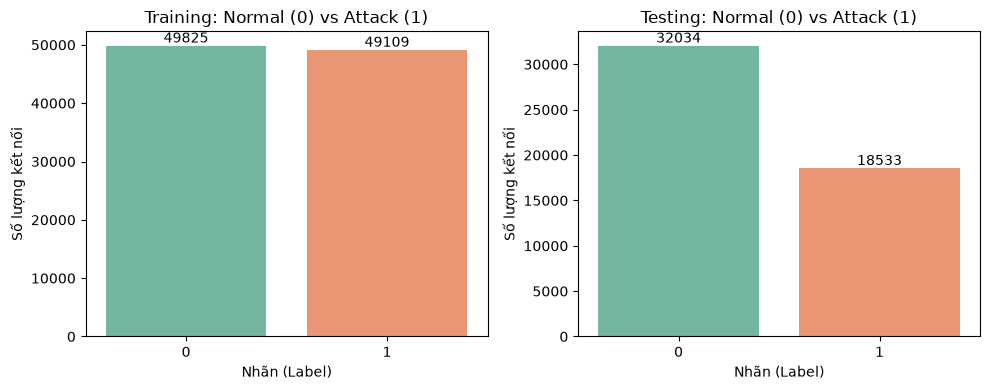

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Xuất bảng thống kê số lượng chính xác
print("Bảng thống kê số lượng luồng mạng (Normal vs Attack):")
display(pd.DataFrame({'Training': train['label'].value_counts(), 'Testing': test['label'].value_counts()}))

# Xuất biểu đồ trực quan
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (split, df) in zip(axes, [('Training', train), ('Testing', test)]):
    sns.countplot(x='label', hue='label', data=df, palette='Set2', legend=False, ax=ax)
    ax.set_title(f'{split}: Normal (0) vs Attack (1)')
    ax.set_xlabel('Nhãn (Label)')
    ax.set_ylabel('Số lượng kết nối')
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=10, color='black')
plt.tight_layout()
plt.show()

In [9]:
# Giá trị phân loại có trong tập test nhưng không có trong tập train
for col in ['proto', 'service', 'state']:
    unseen = sorted(set(test[col].astype(str)) - set(train[col].astype(str)))
    print(f'{col}: {unseen}')

proto: []
service: []


state: ['ACC', 'CLO']


## Ghi chú cho bước tiền xử lý (notebook 02)

- Bước làm sạch **không** encode hay chuẩn hóa dữ liệu. Code `LabelEncoder` / `MinMaxScaler` trước đây (vẫn còn trong `Clean_Data.ipynb`) fit trên toàn bộ dữ liệu, cần làm lại ở notebook 02: **chỉ fit trên tập train**, rồi `transform` tập test.
- Cột `state` trong tập test có giá trị `ACC`, `CLO` không xuất hiện trong tập train (xem cell trên). Encoder cần xử lý được giá trị chưa gặp (ví dụ `OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)`). Không fit encoder trên train + test gộp lại.